# Using the toolkit on real data: Titanic passengers

The other notebooks build `toolkit.py` on a 17-row sample of students. This one applies the same functions, unchanged, to 1,309 Titanic passengers to check they hold up on messier real data: missing values, a skewed distribution, and more rows.

In [1]:
import numpy as np
import pandas as pd
import toolkit

passengers = pd.read_csv('titanic3.csv', na_values='?')
passengers[['age', 'fare']].isna().sum()

age     263
fare      1
dtype: int64

## Age

263 passengers have no recorded age. The toolkit functions drop missing values on their own, so the column can be passed in as-is.

In [2]:
toolkit.show_eda(passengers.age)

Minimum: 0.17
Maximum: 80.0
Mean:    29.88
Median:  28.0
Mode:    24.0


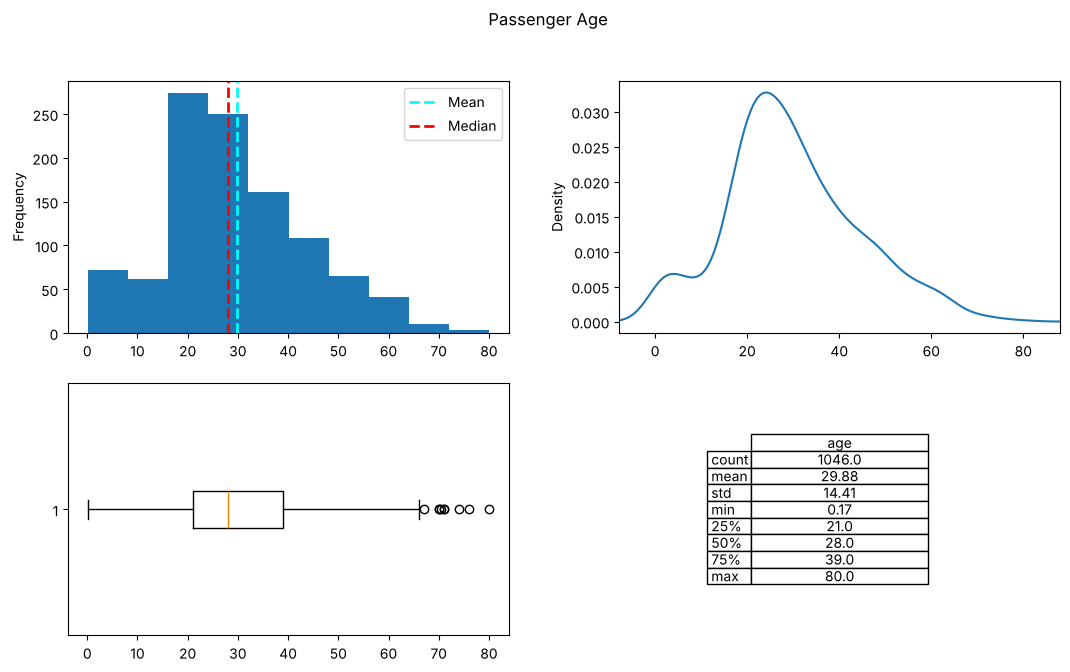

In [3]:
toolkit.show_distribution_profile(passengers.age, title='Passenger Age')

Ages cluster in the 20s and 30s, with a second small bump of young children. The mean and median are close (about 30 and 28), so the distribution is only slightly skewed.

## Fare

Fares behave very differently: a few first-class tickets cost over £500.

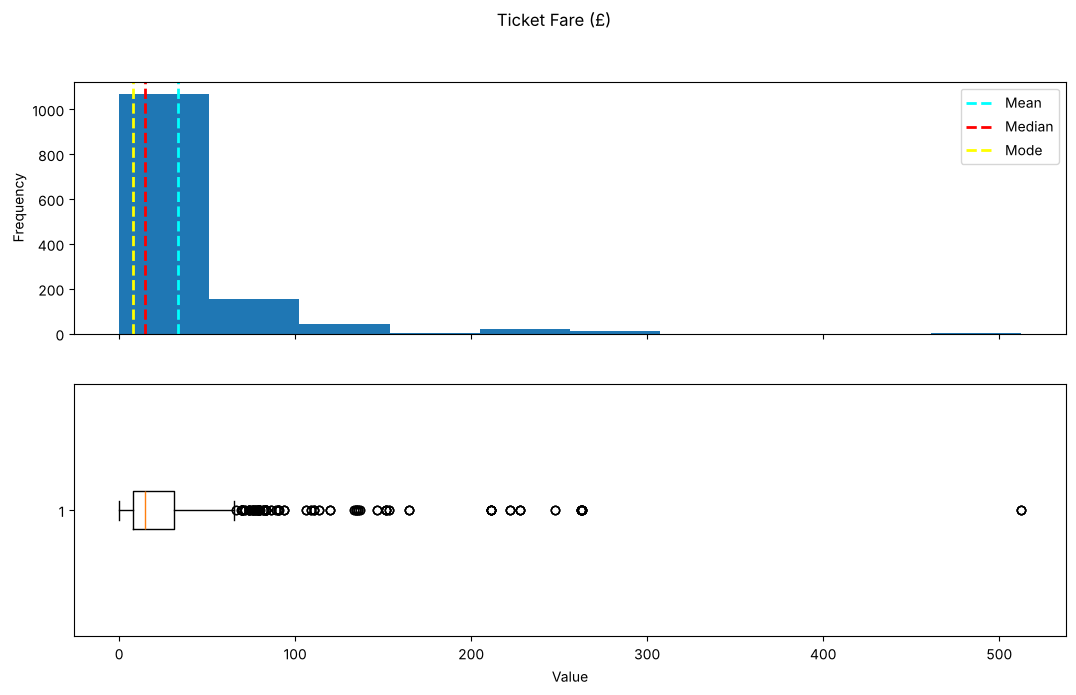

In [4]:
toolkit.show_distribution(passengers.fare, title='Ticket Fare (£)')

In [5]:
print(f"Mean fare:   £{passengers.fare.mean():.2f}")
print(f"Median fare: £{passengers.fare.median():.2f}")

Mean fare:   £33.30
Median fare: £14.45


The mean is more than twice the median: a handful of very expensive tickets pull the average up. For skewed data like this, the median is the better summary of a "typical" fare, and a log scale makes the shape easier to see:

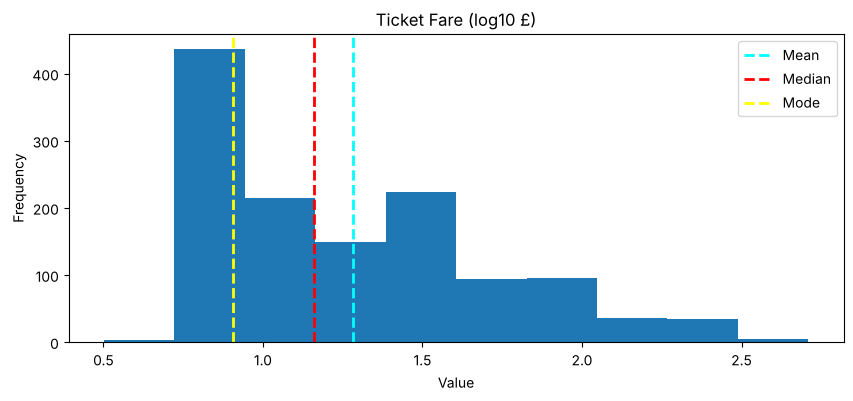

In [6]:
toolkit.show_histogram(np.log10(passengers.fare[passengers.fare > 0]), title='Ticket Fare (log10 £)')

## Fare by class

`fit_line` gives a quick sense of how strongly two numbers move together. Here: how much does each step down in class (1 → 2 → 3) reduce the fare?

In [7]:
m, b, predict = toolkit.fit_line(passengers.pclass, passengers.fare)
print(f"Fare ≈ {m:.1f} × class + {b:.1f}")
for c in (1, 2, 3):
    print(f"  class {c}: fitted £{predict(c):.0f}, actual median £{passengers.fare[passengers.pclass == c].median():.0f}")

Fare ≈ -34.5 × class + 112.5
  class 1: fitted £78, actual median £60
  class 2: fitted £43, actual median £15
  class 3: fitted £9, actual median £8


The line captures the direction (each step down in class lowers the fare by about £35) but not the shape. It puts second class at £43 when the typical second-class ticket was £15: the real gap is between first class and everyone else, not an even step per class. A straight line is a quick check here, not a model of the relationship.

## Survival rate

`add_passed` flags rows above a threshold. Applied to the `survived` column (0 or 1) with a threshold of 1, it labels each passenger as a survivor or not:

In [8]:
flagged = toolkit.add_passed(passengers, grade_col='survived', threshold=1, name='Survivor')
flagged.groupby('pclass')['Survivor'].mean().map(lambda v: f"{v:.0%}")

pclass
1    62%
2    43%
3    26%
Name: Survivor, dtype: str